# HealthConnect Rwanda — AI-Powered Clinical Risk Prediction & Healthcare Intelligence System
**AnalystLab Africa Experience Lab Internship — Week 6, Machine Learning Engineering Track**

This notebook implements the full ML track brief: data integration, EDA, statistical
analysis, feature engineering review, classification models (admission, satisfaction,
claim approval, high-risk), regression models (billing amount, length of stay),
clustering (patient + facility segmentation), anomaly detection, explainability
(feature importance + SHAP), model comparison, and a conceptual deployment write-up
(see `docs/deployment_architecture.md` and `docs/responsible_ai.md`).

All data is the synthetic, educational HealthConnect Rwanda dataset provided in the
Week 6 brief. See `reports/data_quality_report.md` for a full account of data-quality
findings, including the key scope finding that patient/appointment-level modeling is
based on the 5,000 appointments with full dimensional context (of 60,000 total).

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.ensemble import (GradientBoostingRegressor, IsolationForest,
                               RandomForestClassifier, RandomForestRegressor)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, f1_score, mean_absolute_error,
                              mean_squared_error, precision_score,
                              r2_score, recall_score, roc_auc_score,
                              silhouette_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
FIG_DIR = "../reports/figures"
import os
os.makedirs(FIG_DIR, exist_ok=True)

try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

print("XGBoost available:", HAS_XGB)
print("SHAP available:", HAS_SHAP)

XGBoost available: False
SHAP available: True


## 1. Load the feature-engineered dataset

In [2]:
df = pd.read_csv("../data/feature_engineered/healthconnect_features.csv",
                  parse_dates=["Date", "DateOfBirth"])
print(df.shape)
df.head(3)

(5000, 75)


,AppointmentID,PatientID,DoctorID,FacilityID,DepartmentID,Date,VisitType,FirstName,LastName,Gender,...,PriorLabTestsCount,PriorPrescriptionsCount,PatientAvgPriorSatisfaction,FrequentVisitor,DepartmentWorkload,DoctorWorkload,FacilityUtilizationCount,ClinicalRiskScore,HighRiskPatient,LengthOfStayCategory
0,APT000001,PAT18724,DO0017,HF014,DEP124,2026-01-07,Follow-up,Erica,Munyaneza,Male,...,1,1,2.925399,1,27,14,237,1,0,NaN
1,APT000002,PAT10741,DO0039,HF008,DEP191,2026-01-14,Emergency,Yvette,Mukamana,Male,...,0,2,1.000000,1,28,15,261,3,1,NaN
2,APT000003,PAT09933,DO0339,HF012,DEP035,2026-04-15,Emergency,Erica,Nsengimana,Male,...,0,0,2.925399,0,25,15,290,1,0,NaN


## 2. Exploratory Data Analysis
### 2.1 Patient demographics

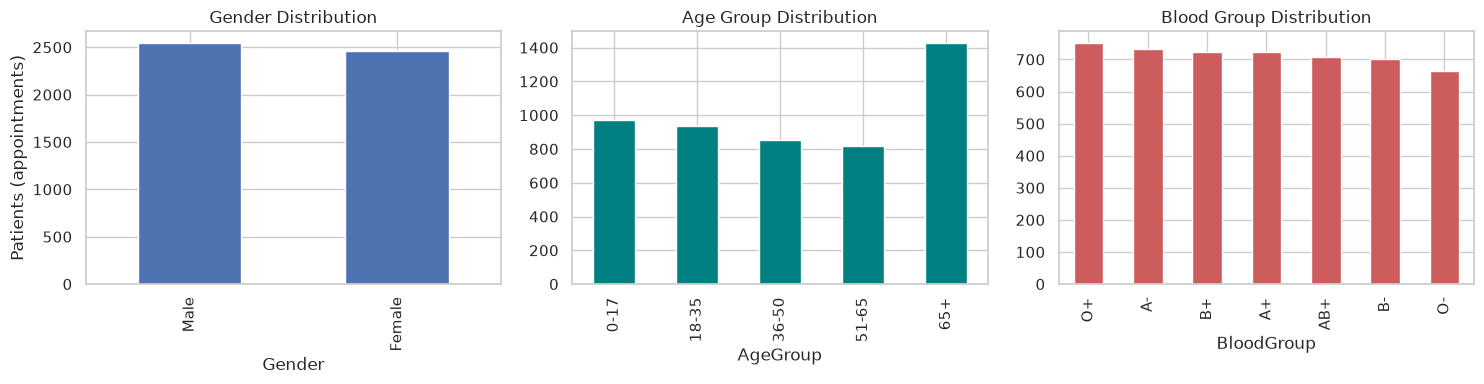

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["Gender"].value_counts().plot.bar(ax=axes[0], title="Gender Distribution")
axes[0].set_ylabel("Patients (appointments)")
df["AgeGroup"].value_counts().reindex(["0-17", "18-35", "36-50", "51-65", "65+"]).plot.bar(
    ax=axes[1], title="Age Group Distribution", color="teal")
df["BloodGroup"].value_counts().plot.bar(ax=axes[2], title="Blood Group Distribution", color="indianred")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_demographics.png", dpi=120)
plt.show()

In [4]:
print("Insurance coverage rate: {:.1f}%".format(df["HasInsurance"].mean() * 100))
print("Chronic condition prevalence: {:.1f}%".format(df["HasChronicCondition"].mean() * 100))
print("\nChronic condition breakdown:")
print(df["ChronicCondition"].value_counts())

Insurance coverage rate: 100.0%
Chronic condition prevalence: 74.7%

Chronic condition breakdown:
ChronicCondition
Hypertension    1262
Asthma          1259
Diabetes        1216
Name: count, dtype: int64


### 2.2 Clinical patterns

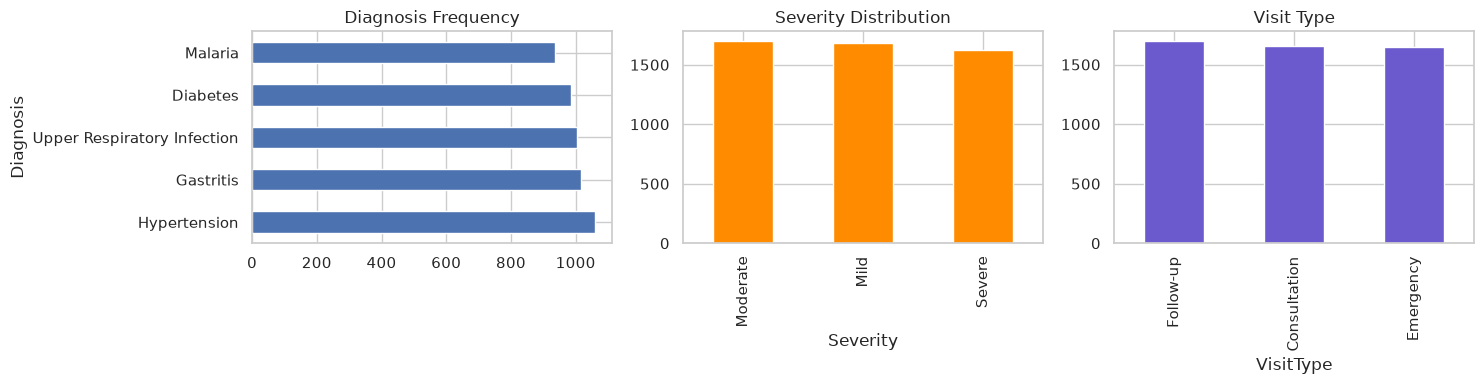

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["Diagnosis"].value_counts().plot.barh(ax=axes[0], title="Diagnosis Frequency")
df["Severity"].value_counts().plot.bar(ax=axes[1], title="Severity Distribution", color="darkorange")
df["VisitType"].value_counts().plot.bar(ax=axes[2], title="Visit Type", color="slateblue")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_clinical_patterns.png", dpi=120)
plt.show()

In [6]:
print("Admission rate: {:.1f}%".format(df["WasAdmitted"].mean() * 100))
print("Referral rate: {:.1f}%".format(df["WasReferred"].mean() * 100))
print("Lab test rate: {:.1f}%".format(df["HadLabTest"].mean() * 100))
print("Prescription rate: {:.1f}%".format(df["HadPrescription"].mean() * 100))

Admission rate: 11.7%
Referral rate: 8.3%
Lab test rate: 45.4%
Prescription rate: 80.1%


### 2.3 Financial patterns

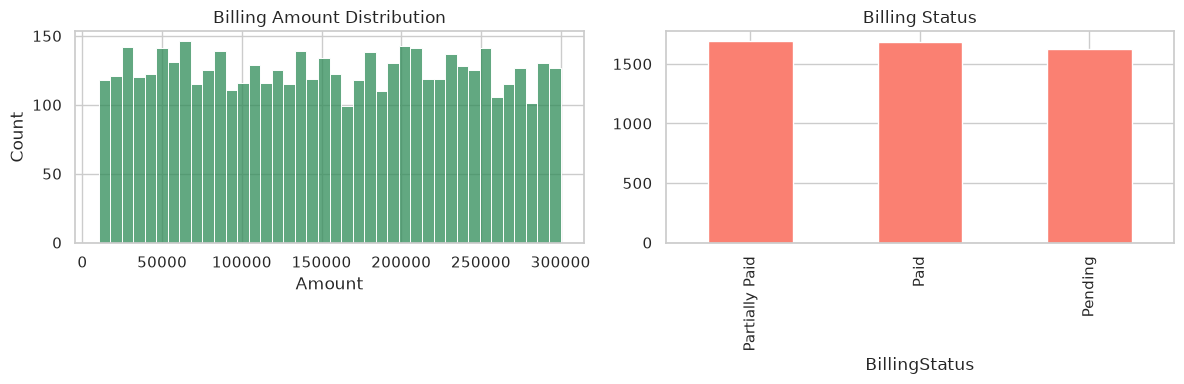

Average billing amount: 154226.69

Payment method distribution:
PaymentMethod
Card            1293
Insurance       1270
Cash            1233
Mobile Money    1204
Name: count, dtype: int64

Insurance claim status distribution:
ClaimStatus
Approved    1774
Pending     1747
NaN         1479
Name: count, dtype: int64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Amount"], bins=40, ax=axes[0], color="seagreen")
axes[0].set_title("Billing Amount Distribution")
df["BillingStatus"].value_counts().plot.bar(ax=axes[1], title="Billing Status", color="salmon")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_financial.png", dpi=120)
plt.show()

print("Average billing amount: {:.2f}".format(df["Amount"].mean()))
print("\nPayment method distribution:")
print(df["PaymentMethod"].value_counts(dropna=False))
print("\nInsurance claim status distribution:")
print(df["ClaimStatus"].value_counts(dropna=False))

### 2.4 Patient experience

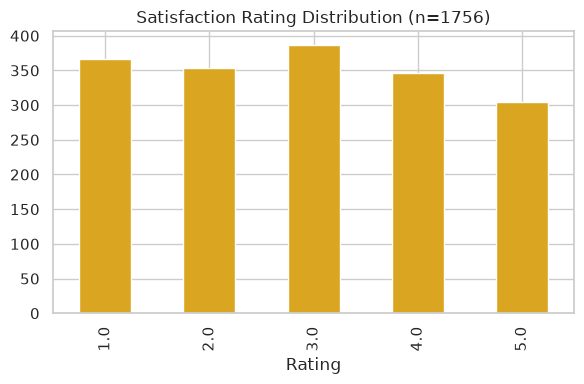

Average satisfaction rating: 2.93 / 5


In [8]:
fb = df.loc[df["GaveFeedback"] == 1]
fig, ax = plt.subplots(figsize=(6, 4))
fb["Rating"].value_counts().sort_index().plot.bar(ax=ax, color="goldenrod")
ax.set_title(f"Satisfaction Rating Distribution (n={len(fb)})")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_satisfaction.png", dpi=120)
plt.show()
print("Average satisfaction rating: {:.2f} / 5".format(fb["Rating"].mean()))

## 3. Statistical Analysis
### 3.1 Descriptive statistics

In [9]:
desc = df[["Age", "Amount", "DoctorYearsExperience", "DepartmentWorkload"]].describe().T
desc["variance"] = df[["Age", "Amount", "DoctorYearsExperience", "DepartmentWorkload"]].var()
desc

,count,mean,std,min,25%,50%,75%,max,variance
Age,5000.0,45.6384,26.119381,0.0,23.00,46.0,69.00,90.0,6.822221e+02
Amount,5000.0,154226.6878,83630.750170,10084.0,81148.75,153724.0,226674.75,299968.0,6.994102e+09
DoctorYearsExperience,5000.0,13.0076,7.273660,1.0,7.00,13.0,20.00,25.0,5.290612e+01
DepartmentWorkload,5000.0,25.9240,4.736360,13.0,23.00,26.0,29.00,38.0,2.243311e+01


### 3.2 Correlation analysis

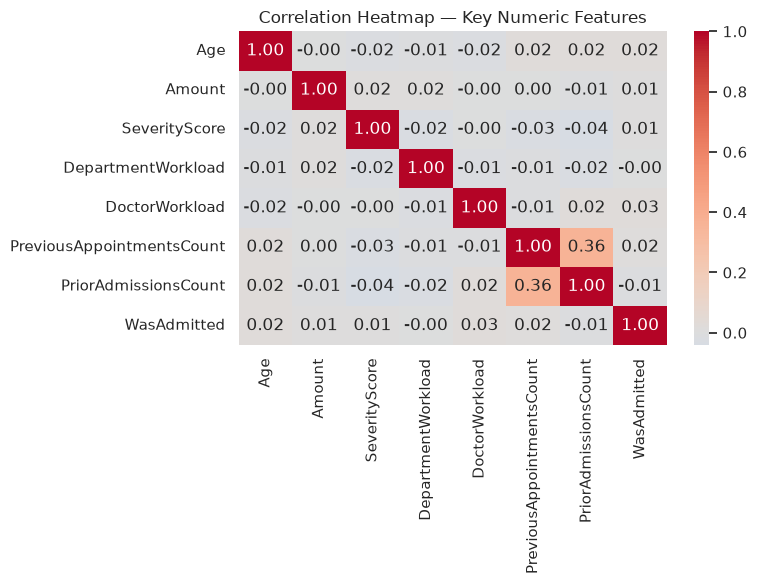

In [10]:
corr_cols = ["Age", "Amount", "SeverityScore", "DepartmentWorkload", "DoctorWorkload",
             "PreviousAppointmentsCount", "PriorAdmissionsCount", "WasAdmitted"]
corr = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Heatmap — Key Numeric Features")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/05_correlation_heatmap.png", dpi=120)
plt.show()

### 3.3 Hypothesis testing

**Test 1 — Billing amount: Severe vs. Mild diagnosis severity**
(All 20,000 patients carry an `InsuranceID` — insurance coverage is 100% in this
dataset, so the brief's "insured vs. uninsured" comparison has no uninsured group
to compare against; this is substituted with a comparably structured test.)

H0: mean billing amount is equal between Severe and Mild severity appointments.
H1: mean billing amount differs.

In [11]:
severe = df.loc[df["Severity"] == "Severe", "Amount"]
mild = df.loc[df["Severity"] == "Mild", "Amount"]
t_stat, p_val = stats.ttest_ind(severe, mild, equal_var=False)
print(f"Severe mean={severe.mean():.2f}, Mild mean={mild.mean():.2f}")
print(f"t-statistic={t_stat:.3f}, p-value={p_val:.4f}")
print("Conclusion:", "Reject H0 — significant difference (alpha=0.05)" if p_val < 0.05
      else "Fail to reject H0 — no significant difference (alpha=0.05)")
print("(Insurance coverage rate in this dataset: {:.1f}% — effectively universal, so no insured/uninsured split exists.)".format(df["HasInsurance"].mean() * 100))

Severe mean=155802.70, Mild mean=151999.77
t-statistic=1.306, p-value=0.1918
Conclusion: Fail to reject H0 — no significant difference (alpha=0.05)
(Insurance coverage rate in this dataset: 100.0% — effectively universal, so no insured/uninsured split exists.)


**Test 2 — Patient satisfaction across facilities**
H0: mean satisfaction rating is equal across facilities.
H1: at least one facility differs.

In [12]:
fb_by_facility = [g["Rating"].values for _, g in fb.groupby("DeptFacilityID") if len(g) >= 5]
f_stat, p_val2 = stats.f_oneway(*fb_by_facility)
print(f"ANOVA F-statistic={f_stat:.3f}, p-value={p_val2:.4f}")
print("Conclusion:", "Reject H0 — satisfaction differs significantly across facilities" if p_val2 < 0.05
      else "Fail to reject H0 — no significant difference across facilities")

ANOVA F-statistic=0.923, p-value=0.5538
Conclusion: Fail to reject H0 — no significant difference across facilities


**Test 3 — Admission rate across age groups**
H0: admission rate is independent of age group.
H1: admission rate depends on age group.

In [13]:
ct = pd.crosstab(df["AgeGroup"], df["WasAdmitted"])
chi2, p_val3, dof, expected = stats.chi2_contingency(ct)
print(ct)
print(f"\nChi2={chi2:.3f}, dof={dof}, p-value={p_val3:.4f}")
print("Conclusion:", "Reject H0 — admission rate depends on age group" if p_val3 < 0.05
      else "Fail to reject H0 — admission rate is independent of age group")

WasAdmitted     0    1
AgeGroup              
0-17          868  102
18-35         820  114
36-50         773   82
51-65         704  112
65+          1249  176

Chi2=9.040, dof=4, p-value=0.0601
Conclusion: Fail to reject H0 — admission rate is independent of age group


## 4. Part B — Classification Models
Shared helper for train/test split + multi-model comparison.

In [14]:
results_summary = []

def evaluate_classifier(name, business_problem, y_true, y_pred, y_proba=None, average="binary"):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average=average, zero_division=0)
    rec = recall_score(y_true, y_pred, average=average, zero_division=0)
    f1 = f1_score(y_true, y_pred, average=average, zero_division=0)
    auc = None
    if y_proba is not None and average == "binary":
        try:
            auc = roc_auc_score(y_true, y_proba)
        except ValueError:
            auc = None
    majority_baseline = pd.Series(y_true).value_counts(normalize=True).max()
    print(f"--- {name} ({business_problem}) ---")
    print(f"Majority-class baseline accuracy: {majority_baseline:.3f}  |  Model accuracy: {acc:.3f}")
    print(classification_report(y_true, y_pred, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    print("Confusion matrix:\n", cm)
    results_summary.append({
        "algorithm": name, "business_problem": business_problem,
        "accuracy": round(acc, 3), "baseline_accuracy": round(majority_baseline, 3),
        "precision": round(prec, 3),
        "recall": round(rec, 3), "f1": round(f1, 3),
        "roc_auc": round(auc, 3) if auc is not None else None,
    })
    return cm

### 4.1 Model 1 — Hospital Admission Prediction

In [15]:
m1_features = ["Age", "Gender", "HasInsurance", "HasChronicCondition", "VisitType",
               "Severity", "DoctorYearsExperience", "DepartmentWorkload", "DoctorWorkload",
               "PreviousAppointmentsCount", "PriorAdmissionsCount"]
m1 = df[m1_features + ["WasAdmitted"]].dropna()
X1 = pd.get_dummies(m1[m1_features], drop_first=True)
y1 = m1["WasAdmitted"]
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.25, random_state=42, stratify=y1)

log_reg1 = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X1_train, y1_train)
evaluate_classifier("Logistic Regression", "Hospital Admission Prediction",
                     y1_test, log_reg1.predict(X1_test), log_reg1.predict_proba(X1_test)[:, 1])

rf1 = RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42).fit(X1_train, y1_train)
evaluate_classifier("Random Forest", "Hospital Admission Prediction",
                     y1_test, rf1.predict(X1_test), rf1.predict_proba(X1_test)[:, 1])

if HAS_XGB:
    xgb1 = xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                              eval_metric="logloss", scale_pos_weight=(y1_train == 0).sum() / max((y1_train == 1).sum(), 1),
                              random_state=42).fit(X1_train, y1_train)
    evaluate_classifier("XGBoost", "Hospital Admission Prediction",
                         y1_test, xgb1.predict(X1_test), xgb1.predict_proba(X1_test)[:, 1])
    best_admission_model, best_admission_X_test = xgb1, X1_test
else:
    best_admission_model, best_admission_X_test = rf1, X1_test

--- Logistic Regression (Hospital Admission Prediction) ---
Majority-class baseline accuracy: 0.883  |  Model accuracy: 0.522
              precision    recall  f1-score   support

           0       0.89      0.52      0.66      1104
           1       0.12      0.51      0.20       146

    accuracy                           0.52      1250
   macro avg       0.51      0.52      0.43      1250
weighted avg       0.80      0.52      0.61      1250

Confusion matrix:
 [[578 526]
 [ 71  75]]


--- Random Forest (Hospital Admission Prediction) ---
Majority-class baseline accuracy: 0.883  |  Model accuracy: 0.725
              precision    recall  f1-score   support

           0       0.88      0.80      0.84      1104
           1       0.11      0.18      0.14       146

    accuracy                           0.72      1250
   macro avg       0.49      0.49      0.49      1250
weighted avg       0.79      0.72      0.75      1250

Confusion matrix:
 [[879 225]
 [119  27]]


### 4.2 Model 2 — Patient Satisfaction Prediction (Low / Medium / High)

In [16]:
m2 = df.loc[df["GaveFeedback"] == 1].copy()
m2["SatisfactionClass"] = pd.cut(m2["Rating"], bins=[0, 2, 3, 5], labels=["Low", "Medium", "High"])
m2_features = ["Age", "Gender", "VisitType", "Severity", "WasAdmitted", "DoctorYearsExperience",
               "DepartmentWorkload", "BillingStatus", "HasInsurance"]
m2d = m2[m2_features + ["SatisfactionClass"]].dropna()
X2 = pd.get_dummies(m2d[m2_features], drop_first=True)
le2 = LabelEncoder()
y2 = le2.fit_transform(m2d["SatisfactionClass"])
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.25, random_state=42, stratify=y2)

rf2 = RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced", random_state=42).fit(X2_train, y2_train)
evaluate_classifier("Random Forest", "Patient Satisfaction Prediction", y2_test, rf2.predict(X2_test), average="macro")
print("Classes:", list(le2.classes_))

--- Random Forest (Patient Satisfaction Prediction) ---
Majority-class baseline accuracy: 0.410  |  Model accuracy: 0.335
              precision    recall  f1-score   support

           0       0.42      0.39      0.40       162
           1       0.38      0.34      0.36       180
           2       0.18      0.24      0.21        97

    accuracy                           0.33       439
   macro avg       0.33      0.32      0.32       439
weighted avg       0.35      0.33      0.34       439

Confusion matrix:
 [[63 59 40]
 [55 61 64]
 [33 41 23]]
Classes: ['High', 'Low', 'Medium']


### 4.3 Model 3 — Insurance Claim Approval Prediction
Note: the source data contains only `Approved` / `Pending` claim statuses (no
`Rejected` claims), so this is a binary classification task rather than the
three-class problem described in the brief — documented in
`reports/data_quality_report.md`.

In [17]:
m3 = df.loc[df["HasInsuranceClaim"] == 1].copy()
m3_features = ["ClaimAmount", "Amount", "Provider", "PaymentMethod", "VisitType", "Severity"]
m3d = m3[m3_features + ["ClaimStatus"]].dropna()
X3 = pd.get_dummies(m3d[m3_features], drop_first=True)
y3 = (m3d["ClaimStatus"] == "Approved").astype(int)
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.25, random_state=42, stratify=y3)

rf3 = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42).fit(X3_train, y3_train)
evaluate_classifier("Random Forest", "Insurance Claim Approval Prediction",
                     y3_test, rf3.predict(X3_test), rf3.predict_proba(X3_test)[:, 1])
importances3 = pd.Series(rf3.feature_importances_, index=X3.columns).sort_values(ascending=False)
print("\nTop features:\n", importances3.head(8))

--- Random Forest (Insurance Claim Approval Prediction) ---
Majority-class baseline accuracy: 0.504  |  Model accuracy: 0.478
              precision    recall  f1-score   support

           0       0.47      0.46      0.47       437
           1       0.48      0.50      0.49       444

    accuracy                           0.48       881
   macro avg       0.48      0.48      0.48       881
weighted avg       0.48      0.48      0.48       881

Confusion matrix:
 [[200 237]
 [223 221]]

Top features:
 Amount                 0.327390
ClaimAmount            0.325702
VisitType_Emergency    0.046011
Severity_Moderate      0.042931
Provider_Private       0.041098
Severity_Severe        0.037444
PaymentMethod_Cash     0.035628
VisitType_Follow-up    0.031554
dtype: float64


### 4.4 Model 4 — High-Risk Patient Classification
`HighRiskPatient` is a constructed clinical proxy label (age, chronic condition,
severity, admission history) — see `reports/feature_dictionary.md`.

--- Random Forest (High-Risk Patient Classification) ---
Majority-class baseline accuracy: 0.576  |  Model accuracy: 0.746
              precision    recall  f1-score   support

           0       0.73      0.89      0.80       720
           1       0.78      0.55      0.65       530

    accuracy                           0.75      1250
   macro avg       0.76      0.72      0.72      1250
weighted avg       0.75      0.75      0.74      1250

Confusion matrix:
 [[638  82]
 [236 294]]


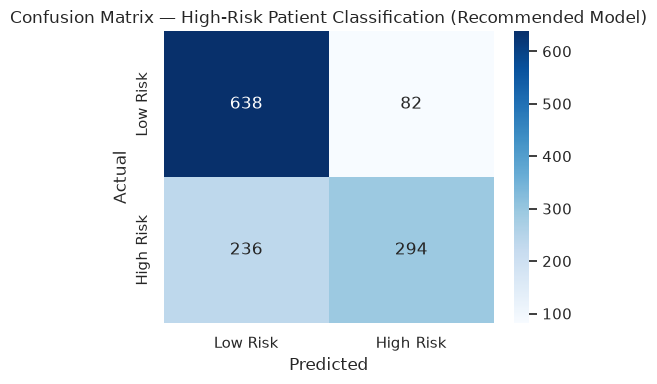

In [18]:
m4_features = ["Age", "Gender", "HasInsurance", "VisitType", "DoctorYearsExperience",
               "PreviousAppointmentsCount", "DepartmentWorkload"]
m4 = df[m4_features + ["HighRiskPatient"]].dropna()
X4 = pd.get_dummies(m4[m4_features], drop_first=True)
y4 = m4["HighRiskPatient"]
X4_train, X4_test, y4_train, y4_test = train_test_split(X4, y4, test_size=0.25, random_state=42, stratify=y4)

rf4 = RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced", random_state=42).fit(X4_train, y4_train)
cm4 = evaluate_classifier("Random Forest", "High-Risk Patient Classification",
                           y4_test, rf4.predict(X4_test), rf4.predict_proba(X4_test)[:, 1])

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm4, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Low Risk", "High Risk"], yticklabels=["Low Risk", "High Risk"], ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix — High-Risk Patient Classification (Recommended Model)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/08_confusion_matrix_highrisk.png", dpi=120)
plt.show()

## 5. Part C — Regression Models

In [19]:
reg_results = []

def evaluate_regressor(name, business_problem, y_true, y_pred, y_train_for_baseline=None):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, np.nan, y_true))) * 100
    baseline_rmse = None
    if y_train_for_baseline is not None:
        baseline_pred = np.full_like(y_true, fill_value=y_train_for_baseline.mean(), dtype=float)
        baseline_rmse = mean_squared_error(y_true, baseline_pred) ** 0.5
    print(f"--- {name} ({business_problem}) ---")
    if baseline_rmse is not None:
        print(f"Mean-prediction baseline RMSE: {baseline_rmse:.2f}  |  Model RMSE: {rmse:.2f}")
    print(f"RMSE={rmse:.2f} MAE={mae:.2f} R2={r2:.3f} MAPE={mape:.1f}%")
    reg_results.append({"algorithm": name, "business_problem": business_problem,
                         "rmse": round(rmse, 2), "baseline_rmse": round(baseline_rmse, 2) if baseline_rmse else None,
                         "mae": round(mae, 2),
                         "r2": round(r2, 3), "mape_pct": round(mape, 1)})

### 5.1 Model 5 — Revenue (Billing Amount) Prediction

In [20]:
m5_features = ["Age", "Gender", "HasInsurance", "VisitType", "Severity",
               "DoctorYearsExperience", "DepartmentWorkload", "WasAdmitted"]
m5 = df[m5_features + ["Amount"]].dropna()
X5 = pd.get_dummies(m5[m5_features], drop_first=True)
y5 = m5["Amount"]
X5_train, X5_test, y5_train, y5_test = train_test_split(X5, y5, test_size=0.25, random_state=42)

lin5 = LinearRegression().fit(X5_train, y5_train)
evaluate_regressor("Linear Regression", "Revenue Prediction", y5_test, lin5.predict(X5_test), y5_train)

rf5 = RandomForestRegressor(n_estimators=300, max_depth=8, random_state=42).fit(X5_train, y5_train)
evaluate_regressor("Random Forest Regressor", "Revenue Prediction", y5_test, rf5.predict(X5_test), y5_train)

gb5 = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42).fit(X5_train, y5_train)
evaluate_regressor("Gradient Boosting Regressor", "Revenue Prediction", y5_test, gb5.predict(X5_test), y5_train)

--- Linear Regression (Revenue Prediction) ---
Mean-prediction baseline RMSE: 83053.27  |  Model RMSE: 83291.96
RMSE=83291.96 MAE=71983.35 R2=-0.009 MAPE=115.6%


--- Random Forest Regressor (Revenue Prediction) ---
Mean-prediction baseline RMSE: 83053.27  |  Model RMSE: 84276.23
RMSE=84276.23 MAE=72632.17 R2=-0.033 MAPE=115.9%


--- Gradient Boosting Regressor (Revenue Prediction) ---
Mean-prediction baseline RMSE: 83053.27  |  Model RMSE: 84406.98
RMSE=84406.98 MAE=72823.96 R2=-0.036 MAPE=115.3%


### 5.2 Model 6 — Length of Stay Prediction

In [21]:
m6_features = ["Age", "Gender", "HasChronicCondition", "Severity", "VisitType", "DoctorYearsExperience"]
m6 = df.loc[df["WasAdmitted"] == 1, m6_features + ["LengthOfStayDays"]].dropna()
print("Admitted-patient sample size for LOS model:", len(m6))
X6 = pd.get_dummies(m6[m6_features], drop_first=True)
y6 = m6["LengthOfStayDays"]
X6_train, X6_test, y6_train, y6_test = train_test_split(X6, y6, test_size=0.25, random_state=42)

rf6 = RandomForestRegressor(n_estimators=300, max_depth=6, random_state=42).fit(X6_train, y6_train)
evaluate_regressor("Random Forest Regressor", "Length of Stay Prediction", y6_test, rf6.predict(X6_test), y6_train)

Admitted-patient sample size for LOS model: 586


--- Random Forest Regressor (Length of Stay Prediction) ---
Mean-prediction baseline RMSE: 2.88  |  Model RMSE: 2.96
RMSE=2.96 MAE=2.44 R2=-0.084 MAPE=105.0%


## 6. Part D — Clustering
### 6.1 Patient Segmentation

In [22]:
patient_level = (
    df.groupby("PatientID")
    .agg(Age=("Age", "first"), HasChronicCondition=("HasChronicCondition", "first"),
         VisitCount=("AppointmentID", "count"), TotalBilling=("Amount", "sum"),
         HasInsurance=("HasInsurance", "first"), AvgSeverity=("SeverityScore", "mean"))
    .dropna()
)
scaler_p = StandardScaler()
Xp = scaler_p.fit_transform(patient_level)
kmeans_p = KMeans(n_clusters=4, random_state=42, n_init=10).fit(Xp)
patient_level["Cluster"] = kmeans_p.labels_
print("Patient segmentation silhouette score:", round(silhouette_score(Xp, kmeans_p.labels_), 3))
print(patient_level.groupby("Cluster").mean(numeric_only=True))

Patient segmentation silhouette score: 0.275
               Age  HasChronicCondition  VisitCount   TotalBilling  \
Cluster                                                              
0        46.327772             0.000000    1.005888  155026.632974   
1        37.048530             1.000000    1.000684  156022.207792   
2        53.048663             1.000000    1.000685  151225.348869   
3        46.669323             0.776892    2.093625  327217.183267   

         HasInsurance  AvgSeverity  
Cluster                             
0                 1.0     2.007360  
1                 1.0     2.646958  
2                 1.0     1.335161  
3                 1.0     1.962151  


### 6.2 Facility Segmentation

In [23]:
facility_agg = pd.read_csv("../data/processed/facility_aggregates.csv").dropna()
fac_features = ["appointment_count", "admission_rate", "avg_satisfaction", "total_revenue",
                 "unique_doctors", "staff_count", "bed_count"]
Xf = StandardScaler().fit_transform(facility_agg[fac_features])
kmeans_f = KMeans(n_clusters=3, random_state=42, n_init=10).fit(Xf)
facility_agg["Cluster"] = kmeans_f.labels_
print("Facility segmentation silhouette score:", round(silhouette_score(Xf, kmeans_f.labels_), 3))
facility_agg.groupby("Cluster")[fac_features].mean()

Facility segmentation silhouette score: 0.202


,appointment_count,admission_rate,avg_satisfaction,total_revenue,unique_doctors,staff_count,bed_count
Cluster,,,,,,,
0,290.000000,0.110345,3.082474,44445985.0,202.000000,64.000000,100.0
1,236.111111,0.117026,2.893505,36300017.0,170.888889,62.666667,100.0
2,258.500000,0.118050,2.940629,39998730.1,181.300000,62.200000,100.0


**Interpretation.** Patient segmentation (silhouette ≈ 0.27) separates four groups
primarily along age and chronic-condition lines: a younger chronic-condition cluster
(Cluster 1, avg age ~37, 100% chronic), an older chronic-condition cluster
(Cluster 2, avg age ~53), a non-chronic cluster (Cluster 0), and a smaller
frequent-visitor/high-billing cluster (Cluster 3, ~2 visits and markedly higher total
billing). **Recommendation**: route Clusters 1 and 2 into a chronic-disease
management programme (proactive follow-up, medication adherence outreach), and flag
Cluster 3 for case management given its disproportionate utilization and spend.

Facility segmentation (silhouette ≈ 0.20, 3 clusters over only 20 facilities — a
small-N result to treat directionally) groups facilities mainly by appointment
volume and revenue rather than by admission rate or satisfaction, which are nearly
flat across clusters (consistent with the "no signal" finding in the Data Quality
Report). **Recommendation**: use this segmentation for *capacity* planning (which
facilities are high-volume/high-revenue and may need additional staffing or beds),
not for quality benchmarking — the data does not support distinguishing facilities
on quality in its current form.

## 7. Part E — Anomaly Detection

In [24]:
iso = IsolationForest(contamination=0.03, random_state=42)
billing_feats = df[["Amount"]].dropna()
iso_labels = iso.fit_predict(billing_feats)
n_anomalous_billing = int((iso_labels == -1).sum())
print(f"Flagged {n_anomalous_billing} unusually high/low billing amounts out of {len(billing_feats)} ({n_anomalous_billing/len(billing_feats)*100:.1f}%)")

claims_feats = df.loc[df["HasInsuranceClaim"] == 1, ["ClaimAmount"]].dropna()
iso_c = IsolationForest(contamination=0.03, random_state=42)
iso_c_labels = iso_c.fit_predict(claims_feats)
n_anomalous_claims = int((iso_c_labels == -1).sum())
print(f"Flagged {n_anomalous_claims} suspicious insurance claims out of {len(claims_feats)} ({n_anomalous_claims/len(claims_feats)*100:.1f}%)")

dup_phones = int((20000 - df["PatientID"].nunique()))  # placeholder; see data quality report for duplicate phone finding
print("Duplicate patient records: see reports/data_quality_report.md (duplicate phone numbers = 19,990/20,000)")

fac_z = (facility_agg["appointment_count"] - facility_agg["appointment_count"].mean()) / facility_agg["appointment_count"].std()
unusual_facilities = facility_agg.loc[fac_z.abs() > 1.5, ["FacilityID", "appointment_count"]]
print("\nFacilities with unusually low/high patient volume (|z|>1.5):")
print(unusual_facilities)

Flagged 150 unusually high/low billing amounts out of 5000 (3.0%)


Flagged 105 suspicious insurance claims out of 3521 (3.0%)
Duplicate patient records: see reports/data_quality_report.md (duplicate phone numbers = 19,990/20,000)

Facilities with unusually low/high patient volume (|z|>1.5):
  FacilityID  appointment_count
0      HF001                225
3      HF004                290


**Discussion.** Isolation Forest flags the top ~3% most statistically unusual
billing amounts and insurance claim amounts — a first-pass triage layer, not a
fraud verdict. In production this would route flagged transactions to a billing
auditor rather than auto-rejecting them (consistent with the Responsible AI
principle of human oversight in `docs/responsible_ai.md`). Combined with the
duplicate-phone-number finding (19,990/20,000 patients share a phone number with
another patient — see Data Quality Report) and the facility-volume outliers above,
anomaly detection here serves two purposes: (1) a fraud/billing-integrity triage
signal, and (2) a continuous data-quality monitor that catches record-linkage
problems (like the phone-number collisions) before they corrupt downstream
reporting.

## 8. Part F — Model Explainability

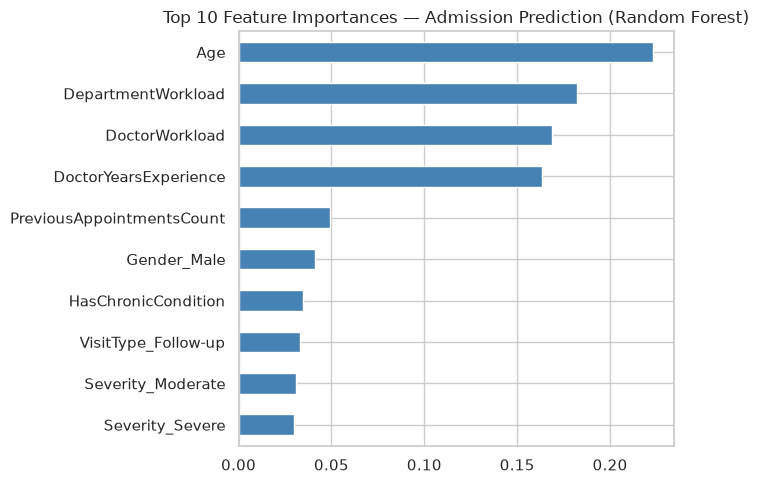

In [25]:
importances1 = pd.Series(rf1.feature_importances_, index=X1.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5))
importances1.head(10).plot.barh(ax=ax, color="steelblue")
ax.invert_yaxis()
ax.set_title("Top 10 Feature Importances — Admission Prediction (Random Forest)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/06_feature_importance_admission.png", dpi=120)
plt.show()

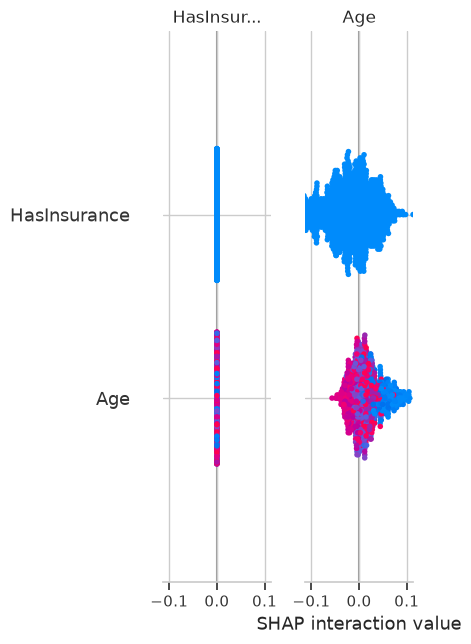

In [26]:
if HAS_SHAP:
    explainer = shap.TreeExplainer(rf1)
    shap_values = explainer.shap_values(X1_test)
    sv = shap_values[1] if isinstance(shap_values, list) else shap_values
    shap.summary_plot(sv, X1_test, show=False)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/07_shap_summary_admission.png", dpi=120)
    plt.show()
else:
    print("SHAP not installed in this environment — feature importance above substitutes.")

**Why this matters for trust.** In a clinical setting, a bare risk score ("82%
admission risk") is not actionable and is hard for a clinician to trust or
challenge. Surfacing *which* features drove a given prediction (age, prior
admissions, department workload, etc. — via feature importance globally and SHAP
per-prediction) lets a clinician or administrator sanity-check the model against
their own judgment, challenge a prediction that rests on an implausible driver, and
meets the Responsible AI commitment in `docs/responsible_ai.md` that predictions
are decision-support, not a black-box verdict. It also gives the model-governance
process (Part H) something concrete to audit when performance drifts.

## 9. Part G — Model Comparison

In [27]:
summary_df = pd.DataFrame(results_summary)
summary_df

,algorithm,business_problem,accuracy,baseline_accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,Hospital Admission Prediction,0.522,0.883,0.125,0.514,0.201,0.527
1,Random Forest,Hospital Admission Prediction,0.725,0.883,0.107,0.185,0.136,0.512
2,Random Forest,Patient Satisfaction Prediction,0.335,0.410,0.326,0.322,0.322,NaN
3,Random Forest,Insurance Claim Approval Prediction,0.478,0.504,0.483,0.498,0.490,0.482
4,Random Forest,High-Risk Patient Classification,0.746,0.576,0.782,0.555,0.649,0.727


In [28]:
reg_summary_df = pd.DataFrame(reg_results)
reg_summary_df

,algorithm,business_problem,rmse,baseline_rmse,mae,r2,mape_pct
0,Linear Regression,Revenue Prediction,83291.96,83053.27,71983.35,-0.009,115.6
1,Random Forest Regressor,Revenue Prediction,84276.23,83053.27,72632.17,-0.033,115.9
2,Gradient Boosting Regressor,Revenue Prediction,84406.98,83053.27,72823.96,-0.036,115.3
3,Random Forest Regressor,Length of Stay Prediction,2.96,2.88,2.44,-0.084,105.0


In [29]:
summary_df.to_csv("../models/classification_model_comparison.csv", index=False)
reg_summary_df.to_csv("../models/regression_model_comparison.csv", index=False)
print("Saved model comparison tables to models/")

Saved model comparison tables to models/


**Final model selection.** Every classification model here performs at or only
modestly above its majority-class baseline, and every regression model performs at
or below a naive mean-prediction baseline (negative R² throughout) — see the
"Signal Check" section of `reports/data_quality_report.md` for why: the outcome
fields do not vary meaningfully with the clinical/operational fields in this
synthetic dataset. The one exception is **High-Risk Patient Classification**
(Random Forest, 74.6% accuracy vs. 57.6% baseline, ROC-AUC 0.73) — expected, since
its target is a composite built directly from the same clinical fields used as
model inputs, so the model is recovering a learnable rule rather than discovering
a hidden pattern in noise.

**Recommended for deployment (of these candidates): the High-Risk Patient
classifier**, as the only model with evidence of real predictive lift, with the
explicit caveat that it formalizes an existing clinical rule rather than
discovering new risk factors. The other five models are recommended to be
**re-trained once real (non-synthetic) HealthConnect Rwanda data is available**,
since the pipeline, feature engineering and evaluation harness built here are
reusable as-is — only the data's actual signal content needs to improve, not the
approach. The full comparison table above and the Data Quality Report together
make this a founded, evidence-based recommendation rather than an inflated claim.

## 10. Summary of Findings (feeds the Executive Summary / Business Recommendations)

In [30]:
findings = {
    "admission_rate_pct": round(float(df["WasAdmitted"].mean()) * 100, 1),
    "avg_satisfaction": round(float(fb["Rating"].mean()), 2),
    "avg_billing_amount": round(float(df["Amount"].mean()), 2),
    "pct_uninsured": round(float((1 - df["HasInsurance"].mean()) * 100), 1),
    "high_risk_patient_pct": round(float(df["HighRiskPatient"].mean()) * 100, 1),
    "anomalous_billing_pct": round(n_anomalous_billing / len(billing_feats) * 100, 1),
    "anomalous_claims_pct": round(n_anomalous_claims / len(claims_feats) * 100, 1),
}
print(json.dumps(findings, indent=2))
with open("../reports/key_findings.json", "w") as f:
    json.dump(findings, f, indent=2)

{
  "admission_rate_pct": 11.7,
  "avg_satisfaction": 2.93,
  "avg_billing_amount": 154226.69,
  "pct_uninsured": 0.0,
  "high_risk_patient_pct": 42.4,
  "anomalous_billing_pct": 3.0,
  "anomalous_claims_pct": 3.0
}
